In [1]:
from google.colab import drive
drive.mount("/content/drive")

%pip install -q ultralytics pyyaml pandas matplotlib

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.6 MB/s eta 0:00:00


In [2]:
import torch
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    raise RuntimeError(
        "GPU not detected. In Colab, select Runtime > Change runtime type > GPU."
    )

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.175
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/deeplearning")
DATASET_DIR = PROJECT_DIR / "Dataset" / "Dataset_for_yolo"

MODELS_DIR = PROJECT_DIR / "models"
OUTPUTS_DIR = PROJECT_DIR / "outputs"
RESULTS_DIR = PROJECT_DIR / "results"

TRAINING_DIR = RESULTS_DIR / "yolov8m_training"
METRICS_DIR = RESULTS_DIR / "metrics"
PLOTS_DIR = RESULTS_DIR / "plots"

for folder in [
    MODELS_DIR,
    OUTPUTS_DIR,
    TRAINING_DIR,
    METRICS_DIR,
    PLOTS_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Dataset:", DATASET_DIR)
print("Training outputs:", TRAINING_DIR)

assert DATASET_DIR.exists(), "Dataset directory not found."

Project: /content/drive/MyDrive/deeplearning
Dataset: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo
Training outputs: /content/drive/MyDrive/deeplearning/results/yolov8m_training


In [4]:
import yaml

TRAIN_IMAGES = DATASET_DIR / "train" / "images"
VAL_IMAGES = DATASET_DIR / "valid" / "images"
TEST_IMAGES = DATASET_DIR / "test" / "images"

for name, path in [
    ("Training", TRAIN_IMAGES),
    ("Validation", VAL_IMAGES),
    ("Test", TEST_IMAGES),
]:
    if not path.is_dir():
        raise FileNotFoundError(f"{name} images directory not found: {path}")

DATA_YAML = RESULTS_DIR / "data_corrected.yaml"

training_config = {
    "path": str(DATASET_DIR.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": ["bottle"],
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(training_config, f, sort_keys=False)

print(DATA_YAML.read_text())

path: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- bottle



In [5]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

def count_images(folder):
    return sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

def count_labels(folder):
    return sum(1 for _ in folder.rglob("*.txt"))

for split, folder in [
    ("train", DATASET_DIR / "train"),
    ("valid", DATASET_DIR / "valid"),
    ("test", DATASET_DIR / "test"),
]:
    images_dir = folder / "images"
    labels_dir = folder / "labels"

    print(
        f"{split}: images={count_images(images_dir)}, "
        f"label_files={count_labels(labels_dir)}"
    )

train: images=4202, label_files=4202
valid: images=401, label_files=400
test: images=200, label_files=200


In [6]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

print("Pretrained YOLOv8m loaded successfully.")

Pretrained YOLOv8m loaded successfully.


In [7]:
import torch
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

results = model.train(
    data=str(DATA_YAML),
    epochs=100,
    imgsz=640,
    batch=8,
    patience=20,
    device=0,
    workers=2,
    seed=SEED,
    project=str(TRAINING_DIR),
    name="plastic_bottle_yolov8m",
    exist_ok=True,
    pretrained=True,
    optimizer="auto",
    amp=True,
    cache=False,
    save=True,
    save_period=10,
    plots=True,
    verbose=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/deeplearning/results/data_corrected.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=plastic_bottle_yolov8m, nb

In [8]:
import shutil

RUN_DIR = TRAINING_DIR / "plastic_bottle_yolov8m"
BEST_CHECKPOINT = RUN_DIR / "weights" / "best.pt"
LAST_CHECKPOINT = RUN_DIR / "weights" / "last.pt"

if not BEST_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found: {BEST_CHECKPOINT}"
    )

SAVED_MODEL = MODELS_DIR / "yolov8m_best.pt"
shutil.copy2(BEST_CHECKPOINT, SAVED_MODEL)

print("Best checkpoint:", BEST_CHECKPOINT)
print("Portable model copy:", SAVED_MODEL)
print("Best model size (MB):", round(SAVED_MODEL.stat().st_size / 1e6, 2))

if LAST_CHECKPOINT.exists():
    print("Last checkpoint:", LAST_CHECKPOINT)

Best checkpoint: /content/drive/MyDrive/deeplearning/results/yolov8m_training/plastic_bottle_yolov8m/weights/best.pt
Portable model copy: /content/drive/MyDrive/deeplearning/models/yolov8m_best.pt
Best model size (MB): 52.03
Last checkpoint: /content/drive/MyDrive/deeplearning/results/yolov8m_training/plastic_bottle_yolov8m/weights/last.pt


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
67,68,9853.40,1.22242,0.54771,0.93991,0.87230,0.82887,0.86623,0.43353,1.62161,0.72675,1.07610,0.000673,0.000673,0.000673
68,69,9997.12,1.22249,0.54925,0.93420,0.85276,0.81395,0.85621,0.42920,1.63786,0.72172,1.08943,0.000654,0.000654,0.000654
69,70,10141.40,1.23483,0.54672,0.93903,0.83910,0.82600,0.85366,0.43296,1.62285,0.70509,1.07273,0.000634,0.000634,0.000634
70,71,10284.90,1.21855,0.54379,0.93777,0.85007,0.82935,0.85744,0.43576,1.60710,0.70907,1.07636,0.000614,0.000614,0.000614
71,72,10432.40,1.20381,0.53908,0.93286,0.87001,0.81549,0.86301,0.43535,1.62776,0.72175,1.08033,0.000594,0.000594,0.000594


Available evaluation metrics: ['metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']


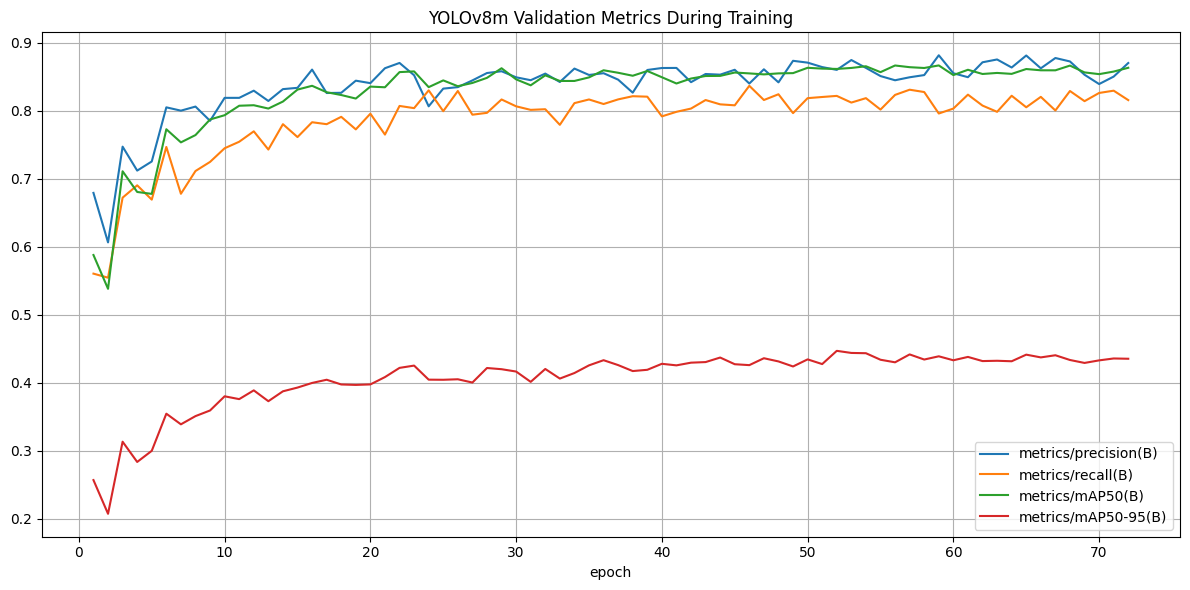

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = RUN_DIR / "results.csv"

if not CSV_PATH.exists():
    raise FileNotFoundError(f"Training metrics not found: {CSV_PATH}")

history = pd.read_csv(CSV_PATH)
history.columns = history.columns.str.strip()

display(history.tail())

metric_columns = [
    col for col in history.columns
    if any(term in col.lower() for term in [
        "precision", "recall", "map50", "map50-95"
    ])
]

print("Available evaluation metrics:", metric_columns)

if metric_columns:
    history.plot(
        x="epoch",
        y=metric_columns,
        figsize=(12, 6),
        grid=True
    )
    plt.title("YOLOv8m Validation Metrics During Training")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "yolov8m_training_metrics.png", dpi=150)
    plt.show()

In [10]:
from ultralytics import YOLO

trained_model = YOLO(str(SAVED_MODEL))

print("Model loaded:", SAVED_MODEL)
print("Model task:", trained_model.task)
print("Model classes:", trained_model.names)

Model loaded: /content/drive/MyDrive/deeplearning/models/yolov8m_best.pt
Model task: detect
Model classes: {0: 'bottle'}
